In [ ]:
# This notebook lives in notebooks/, but it reads and writes data/, models/ and results/
# relative to the repo root, where those folders are gitignored. Move there first so the
# outputs land in the same place as before (and never in notebooks/, which is not ignored).
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
print("Working directory:", Path.cwd())

In [1]:

pip install datasets pandas pillow matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import datasets
import pandas as pd

print("Python:", sys.executable)
print("Datasets version:", datasets.__version__)
print("Pandas version:", pd.__version__)

Python: /Users/uj/Documents/CS5787/Final Project/.venv/bin/python
Datasets version: 5.1.0
Pandas version: 3.1.1


/Users/uj/Documents/CS5787/Final Project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from datasets import load_dataset

dataset = load_dataset(
    "maghzal/PathEval",
    "2D",
    split="train",
    streaming=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
samples = list(dataset.take(5))

print("Number of samples:", len(samples))

if samples:
    print("\nAvailable columns:")
    print(list(samples[0].keys()))

    print("\nFirst sample:")
    for key, value in samples[0].items():
        print(f"{key}: {str(value)[:300]}")

Number of samples: 5

Available columns:
['id', 'image', 'scenario', 'ground truth', 'path 1 descriptors', 'path 2 descriptors']

First sample:
id: 3921
image: combined_images/3/3921_2D.png
scenario: The agent navigating this maze is a large truck, so sharp turns (90 degrees or larger) are harder to make. It should also stay on a straight line (unless it is making a turn) as it is driving through heavy traffic. . Which path better achieves the task?
ground truth: Path 1
path 1 descriptors: {'Average clearance': 7.0996975759, 'Maximum angle': 33.2110440884, 'Maximum clearance': 15.1462363585, 'Minimum clearance': 1.2131486073, 'Path length': 134.8731158783, 'Sharp turns': 0, 'Smoothness': 93.2855861526}
path 2 descriptors: {'Average clearance': 5.1570088681, 'Maximum angle': 110.0897781028, 'Maximum clearance': 15.1462363585, 'Minimum clearance': 1.5081701014, 'Path length': 140.0494693544, 'Sharp turns': 1, 'Smoothness': 266.9925329384}


In [5]:

sample = samples[0]

print("Path 1 descriptors:")
for key, value in sample["path 1 descriptors"].items():
    print(f"{key}: {value}")

print("\nPath 2 descriptors:")
for key, value in sample["path 2 descriptors"].items():
    print(f"{key}: {value}")


Path 1 descriptors:
Average clearance: 7.0996975759
Maximum angle: 33.2110440884
Maximum clearance: 15.1462363585
Minimum clearance: 1.2131486073
Path length: 134.8731158783
Sharp turns: 0
Smoothness: 93.2855861526

Path 2 descriptors:
Average clearance: 5.1570088681
Maximum angle: 110.0897781028
Maximum clearance: 15.1462363585
Minimum clearance: 1.5081701014
Path length: 140.0494693544
Sharp turns: 1
Smoothness: 266.9925329384


In [6]:

def compare_paths(sample, attribute):
    p1 = sample["path 1 descriptors"][attribute]
    p2 = sample["path 2 descriptors"][attribute]

    if p1 < p2:
        return 0  # Path 1
    elif p2 < p1:
        return 1  # Path 2
    else:
        return -1  # Tie

results = []

for sample in samples:
    results.append({
        "id": sample["id"],
        "shorter_path": compare_paths(sample, "Path length"),
        "fewer_sharp_turns": compare_paths(sample, "Sharp turns")
    })

import pandas as pd

labels_df = pd.DataFrame(results)
display(labels_df)


,id,shorter_path,fewer_sharp_turns
0,3921,0,0
1,6809,0,-1
2,2670,1,0
3,8349,0,-1
4,6119,1,1


In [7]:

from huggingface_hub import HfApi

api = HfApi()
repo_id = "maghzal/PathEval"

# List files without downloading the whole dataset
files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Total files:", len(files))

image_path = samples[0]["image"]

print("Expected image:", image_path)
print("Exists in repository:", image_path in files)

print("\nFirst 10 repository files:")
for f in files[:10]:
    print(f)


Total files: 37625
Expected image: combined_images/3/3921_2D.png
Exists in repository: False

First 10 repository files:
.gitattributes
2D/combined_images/.gitattributes
2D/combined_images/0/0_2D.png
2D/combined_images/1/1000_2D.png
2D/combined_images/1/1001_2D.png
2D/combined_images/1/1002_2D.png
2D/combined_images/1/1003_2D.png
2D/combined_images/1/1004_2D.png
2D/combined_images/1/1005_2D.png
2D/combined_images/1/1006_2D.png


Original path: combined_images/3/3921_2D.png
Corrected path: 2D/combined_images/3/3921_2D.png
Image downloaded successfully!
Image size: (960, 480)


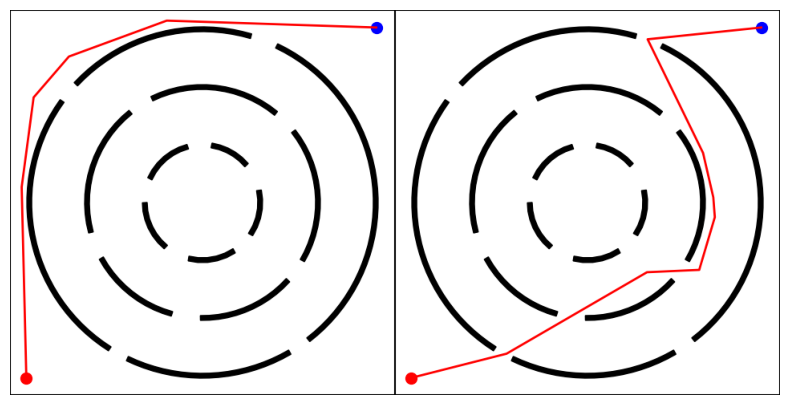

In [8]:

from huggingface_hub import hf_hub_download
from PIL import Image
import matplotlib.pyplot as plt

# Get the image path from the first sample
image_path = samples[0]["image"]

# Add the missing 2D folder
full_image_path = f"2D/{image_path}"

print("Original path:", image_path)
print("Corrected path:", full_image_path)

# Verify the path before downloading
assert full_image_path in files, (
    f"Image not found in repository: {full_image_path}"
)

# Download only this image
local_path = hf_hub_download(
    repo_id="maghzal/PathEval",
    filename=full_image_path,
    repo_type="dataset"
)

# Open and display the image
img = Image.open(local_path).convert("RGB")

print("Image downloaded successfully!")
print("Image size:", img.size)

plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.axis("off")
plt.show()


Path 1 size: (480, 480)
Path 2 size: (480, 480)


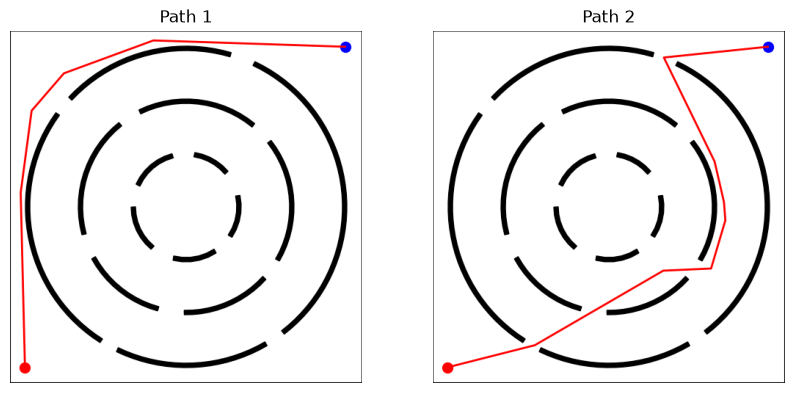

In [9]:

from PIL import Image
import matplotlib.pyplot as plt

# img is the 960x480 image loaded previously
width, height = img.size

assert width == 2 * height, "Unexpected image layout"

# Split into two 480x480 images
path1_img = img.crop((0, 0, width // 2, height))
path2_img = img.crop((width // 2, 0, width, height))

print("Path 1 size:", path1_img.size)
print("Path 2 size:", path2_img.size)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(path1_img)
axes[0].set_title("Path 1")
axes[0].axis("off")

axes[1].imshow(path2_img)
axes[1].set_title("Path 2")
axes[1].axis("off")

plt.show()


In [10]:
for i, sample in enumerate(samples):
    print(
        f"Sample {i}: "
        f"ID = {sample['id']}, "
        f"Image = {sample['image']}"
    )

Sample 0: ID = 3921, Image = combined_images/3/3921_2D.png
Sample 1: ID = 6809, Image = combined_images/6/6809_2D.png
Sample 2: ID = 2670, Image = combined_images/2/2670_2D.png
Sample 3: ID = 8349, Image = combined_images/8/8349_2D.png
Sample 4: ID = 6119, Image = combined_images/6/6119_2D.png


In [11]:

import torch
import transformers

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print("Device:", device)


PyTorch version: 2.15.0
Transformers version: 5.22.2
Device: mps


In [12]:
import sys
import torch
import transformers

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print("Device:", device)

Python: /Users/uj/Documents/CS5787/Final Project/.venv/bin/python
PyTorch: 2.15.0
Transformers: 5.22.2
Device: mps


In [13]:

import torch
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"

# Select device
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print("Using device:", device)

# Load pretrained CLIP
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
clip_model = CLIPModel.from_pretrained(MODEL_NAME)

clip_model = clip_model.to(device)
clip_model.eval()

# Freeze CLIP parameters
for param in clip_model.parameters():
    param.requires_grad = False

print("CLIP loaded successfully!")
print("All parameters frozen:",
      all(not p.requires_grad for p in clip_model.parameters()))


W1108 16:57:25.791000 15068 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Using device: mps


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 35168.29it/s]


CLIP loaded successfully!
All parameters frozen: True


In [14]:

# Use the two cropped images from your previous cells
images = [path1_img, path2_img]

inputs = processor(
    images=images,
    return_tensors="pt",
    padding=True
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.no_grad():
    image_features = clip_model.get_image_features(
        pixel_values=inputs["pixel_values"]
    )

# Some Transformers versions return a model output object
if hasattr(image_features, "pooler_output"):
    image_features = image_features.pooler_output

# Normalize the embeddings
image_features = torch.nn.functional.normalize(
    image_features, p=2, dim=-1
)

print("Features shape:", image_features.shape)

embedding_1 = image_features[0].cpu()
embedding_2 = image_features[1].cpu()

print("Path 1 embedding:", embedding_1.shape)
print("Path 2 embedding:", embedding_2.shape)


Features shape: torch.Size([2, 512])
Path 1 embedding: torch.Size([512])
Path 2 embedding: torch.Size([512])


In [15]:

import torch.nn.functional as F

similarity = F.cosine_similarity(
    embedding_1.unsqueeze(0),
    embedding_2.unsqueeze(0)
).item()

print(f"Cosine similarity: {similarity:.4f}")

print("Embeddings identical:",
      torch.allclose(embedding_1, embedding_2))


Cosine similarity: 0.9822
Embeddings identical: False


In [16]:

import torch

# Combine Path 1 and Path 2 embeddings
pair_features = torch.cat(
    [embedding_1, embedding_2],
    dim=0
)

print("Path 1 shape:", embedding_1.shape)
print("Path 2 shape:", embedding_2.shape)
print("Combined features:", pair_features.shape)

assert pair_features.shape == (1024,)
print("Pairwise feature preparation successful!")


Path 1 shape: torch.Size([512])
Path 2 shape: torch.Size([512])
Combined features: torch.Size([1024])
Pairwise feature preparation successful!


In [17]:

from huggingface_hub import hf_hub_download
from PIL import Image

def load_path_pair(sample):
    image_path = f"2D/{sample['image']}"

    local_path = hf_hub_download(
        repo_id="maghzal/PathEval",
        filename=image_path,
        repo_type="dataset"
    )

    with Image.open(local_path) as image:
        image = image.convert("RGB")

        width, height = image.size
        assert width == 2 * height, (
            f"Unexpected image size: {image.size}"
        )

        path1 = image.crop((0, 0, width // 2, height))
        path2 = image.crop((width // 2, 0, width, height))

    return path1, path2


In [18]:
for sample in samples:
    p1, p2 = load_path_pair(sample)
    print(
        f"Sample {sample['id']}:",
        p1.size,
        p2.size
    )

Sample 3921: (480, 480) (480, 480)
Sample 6809: (480, 480) (480, 480)
Sample 2670: (480, 480) (480, 480)
Sample 8349: (480, 480) (480, 480)
Sample 6119: (480, 480) (480, 480)


In [19]:
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

pilot_samples = list(dataset.take(20))

feature_rows = []
sample_ids = []

clip_model.eval()

for sample in tqdm(pilot_samples):
    path1, path2 = load_path_pair(sample)

    inputs = processor(
        images=[path1, path2],
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.inference_mode():
        features = clip_model.get_image_features(
            pixel_values=pixel_values
        )

        if hasattr(features, "pooler_output"):
            features = features.pooler_output

        features = F.normalize(features, p=2, dim=-1)

    pair_vector = torch.cat(
        [features[0], features[1]], dim=0
    )

    feature_rows.append(pair_vector.cpu())
    sample_ids.append(sample["id"])

X_pilot = torch.stack(feature_rows)

print("Feature matrix:", X_pilot.shape)
print("Number of IDs:", len(sample_ids))

assert X_pilot.shape == (20, 1024)

100%|██████████| 20/20 [00:01<00:00, 16.06it/s]

Feature matrix: torch.Size([20, 1024])
Number of IDs: 20


In [20]:

import pandas as pd
import torch

# Use the same sample order as X_pilot
label_rows = []

for sample in pilot_samples:
    label_rows.append({
        "id": sample["id"],
        "shorter_path": compare_paths(sample, "Path length"),
        "fewer_sharp_turns": compare_paths(sample, "Sharp turns")
    })

pilot_labels = pd.DataFrame(label_rows)

# Verify that features and labels have matching IDs
assert len(pilot_labels) == X_pilot.shape[0]
assert pilot_labels["id"].tolist() == sample_ids

print("Features and labels are aligned!")
print("Feature matrix:", X_pilot.shape)

display(pilot_labels.head(10))

print("\nShorter path distribution:")
print(pilot_labels["shorter_path"].value_counts())

print("\nSharp turns distribution:")
print(pilot_labels["fewer_sharp_turns"].value_counts())


Features and labels are aligned!
Feature matrix: torch.Size([20, 1024])


,id,shorter_path,fewer_sharp_turns
0,3921,0,0
1,6809,0,-1
2,2670,1,0
3,8349,0,-1
4,6119,1,1
5,1616,1,0
6,5887,0,0
7,8960,0,0
8,5041,0,0
9,8325,1,1



Shorter path distribution:
shorter_path
0    12
1     8
Name: count, dtype: int64

Sharp turns distribution:
fewer_sharp_turns
 0    8
-1    8
 1    4
Name: count, dtype: int64


In [21]:

import pandas as pd
from collections import Counter

# Inspect metadata without downloading new images
audit_samples = list(dataset.take(500))

audit_df = pd.DataFrame([
    {
        "id": s["id"],
        "image": s["image"],
        "shorter_path": compare_paths(s, "Path length"),
        "fewer_sharp_turns": compare_paths(s, "Sharp turns")
    }
    for s in audit_samples
])

print("Total records:", len(audit_df))
print("Unique sample IDs:", audit_df["id"].nunique())
print("Unique image paths:", audit_df["image"].nunique())

print("\nRepeated image paths:")
repeated = audit_df["image"].value_counts()
print(repeated[repeated > 1].head(10))

print("\nPath Length Labels:")
print(audit_df["shorter_path"].value_counts())

print("\nSharp Turns Labels:")
print(audit_df["fewer_sharp_turns"].value_counts())


Total records: 500
Unique sample IDs: 500
Unique image paths: 500

Repeated image paths:
Series([], Name: count, dtype: int64)

Path Length Labels:
shorter_path
0    255
1    245
Name: count, dtype: int64

Sharp Turns Labels:
fewer_sharp_turns
-1    276
 0    119
 1    105
Name: count, dtype: int64


In [22]:

import pandas as pd

# Build a table of path descriptors from the 500 samples
descriptor_rows = []

for s in audit_samples:
    descriptor_rows.append({
        "id": s["id"],
        "image": s["image"],
        "path1_length": s["path 1 descriptors"]["Path length"],
        "path2_length": s["path 2 descriptors"]["Path length"],
        "path1_turns": s["path 1 descriptors"]["Sharp turns"],
        "path2_turns": s["path 2 descriptors"]["Sharp turns"]
    })

descriptor_df = pd.DataFrame(descriptor_rows)

# Check exact repeated descriptor combinations
descriptor_cols = [
    "path1_length",
    "path2_length",
    "path1_turns",
    "path2_turns"
]

duplicate_mask = descriptor_df.duplicated(
    subset=descriptor_cols,
    keep=False
)

print("Total samples:", len(descriptor_df))
print("Repeated descriptor records:",
      duplicate_mask.sum())

print("\nExamples of repeated descriptors:")
display(descriptor_df[duplicate_mask].head(10))


Total samples: 500
Repeated descriptor records: 118

Examples of repeated descriptors:


,id,image,path1_length,path2_length,path1_turns,path2_turns
2,2670,combined_images/2/2670_2D.png,141.701240,122.345424,0,1
5,1616,combined_images/1/1616_2D.png,142.084540,139.708211,0,1
9,8325,combined_images/8/8325_2D.png,174.479395,121.709684,1,0
18,6967,combined_images/6/6967_2D.png,119.403577,150.274104,0,0
21,3719,combined_images/3/3719_2D.png,172.266918,149.046654,0,0
31,3169,combined_images/3/3169_2D.png,122.482837,166.400231,0,2
37,1927,combined_images/1/1927_2D.png,135.457680,139.597615,0,0
40,9331,combined_images/9/9331_2D.png,133.760367,164.166454,0,1
44,1430,combined_images/1/1430_2D.png,203.931554,152.216988,3,0
45,9245,combined_images/9/9245_2D.png,177.003293,121.358303,1,0


In [24]:
import sys
import sklearn

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

Python: /Users/uj/Documents/CS5787/Final Project/.venv/bin/python
Scikit-learn: 1.9.1


In [25]:

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Use the descriptor table already created
df = descriptor_df.copy()

descriptor_cols = [
    "path1_length",
    "path2_length",
    "path1_turns",
    "path2_turns"
]

# Group samples with matching descriptor combinations
df["group_id"] = df.groupby(
    descriptor_cols,
    dropna=False
).ngroup()

# Split by group, not by individual row
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        df,
        groups=df["group_id"]
    )
)

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()

# Check overlap
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])

assert train_groups.isdisjoint(val_groups)
assert set(train_df["id"]).isdisjoint(set(val_df["id"]))

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Group overlap:", len(train_groups & val_groups))

print("\nTrain labels:")
print((train_df["path1_length"] >
       train_df["path2_length"]).value_counts())

print("\nValidation labels:")
print((val_df["path1_length"] >
       val_df["path2_length"]).value_counts())


Training samples: 401
Validation samples: 99
Group overlap: 0

Train labels:
False    202
True     199
Name: count, dtype: int64

Validation labels:
False    53
True     46
Name: count, dtype: int64


In [26]:

import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

def extract_features(df, sample_lookup):
    features_list = []
    labels_list = []
    ids_list = []

    clip_model.eval()

    for sample_id in tqdm(df["id"].tolist()):
        sample = sample_lookup[sample_id]

        path1, path2 = load_path_pair(sample)

        inputs = processor(
            images=[path1, path2],
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].to(device)

        with torch.inference_mode():
            features = clip_model.get_image_features(
                pixel_values=pixel_values
            )

            if hasattr(features, "pooler_output"):
                features = features.pooler_output

            features = F.normalize(features, p=2, dim=-1)

        pair_vector = torch.cat(
            [features[0], features[1]], dim=0
        )

        label = compare_paths(sample, "Path length")

        features_list.append(pair_vector.cpu())
        labels_list.append(label)
        ids_list.append(sample_id)

    return (
        torch.stack(features_list),
        torch.tensor(labels_list, dtype=torch.long),
        ids_list
    )

# Create lookup from the same 500 samples
sample_lookup = {s["id"]: s for s in audit_samples}

X_train, y_train, train_ids = extract_features(
    train_df, sample_lookup
)

X_val, y_val, val_ids = extract_features(
    val_df, sample_lookup
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

assert set(train_ids).isdisjoint(set(val_ids))
assert X_train.shape[1] == 1024
assert X_val.shape[1] == 1024


100%|██████████| 99/99 [00:27<00:00,  3.60it/s]

Training: torch.Size([401, 1024]) torch.Size([401])
Validation: torch.Size([99, 1024]) torch.Size([99])


In [27]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

torch.save(
    {
        "X_train": X_train,
        "y_train": y_train,
        "train_ids": train_ids,
        "X_val": X_val,
        "y_val": y_val,
        "val_ids": val_ids
    },
    "data/clip_features_500.pt"
)

print("Features saved!")

Features saved!


In [28]:

import torch
from pathlib import Path

data = torch.load(
    "data/clip_features_500.pt",
    map_location="cpu",
    weights_only=True
)

X_train = data["X_train"].float()
y_train = data["y_train"].long()

X_val = data["X_val"].float()
y_val = data["y_val"].long()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

print("Train labels:", torch.unique(y_train))
print("Val labels:", torch.unique(y_val))

assert X_train.shape[1] == 1024
assert set(y_train.tolist()).issubset({0, 1})
assert set(y_val.tolist()).issubset({0, 1})


Training: torch.Size([401, 1024]) torch.Size([401])
Validation: torch.Size([99, 1024]) torch.Size([99])
Train labels: tensor([0, 1])
Val labels: tensor([0, 1])


In [29]:

import torch.nn as nn

linear_model = nn.Linear(1024, 2)

print(linear_model)


Linear(in_features=1024, out_features=2, bias=True)


In [30]:

import torch.optim as optim

torch.manual_seed(42)

linear_model = nn.Linear(1024, 2)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

epochs = 100

for epoch in range(epochs):
    linear_model.train()

    optimizer.zero_grad()

    outputs = linear_model(X_train)
    loss = criterion(outputs, y_train)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        linear_model.eval()

        with torch.no_grad():
            val_outputs = linear_model(X_val)
            val_predictions = val_outputs.argmax(dim=1)

            val_accuracy = (
                val_predictions == y_val
            ).float().mean().item()

        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )


Epoch  10 | Train Loss: 0.6830 | Val Accuracy: 0.4141
Epoch  20 | Train Loss: 0.6726 | Val Accuracy: 0.4242
Epoch  30 | Train Loss: 0.6631 | Val Accuracy: 0.4242
Epoch  40 | Train Loss: 0.6543 | Val Accuracy: 0.4242
Epoch  50 | Train Loss: 0.6459 | Val Accuracy: 0.4949
Epoch  60 | Train Loss: 0.6379 | Val Accuracy: 0.5253
Epoch  70 | Train Loss: 0.6303 | Val Accuracy: 0.5657
Epoch  80 | Train Loss: 0.6230 | Val Accuracy: 0.5758
Epoch  90 | Train Loss: 0.6161 | Val Accuracy: 0.5960
Epoch 100 | Train Loss: 0.6095 | Val Accuracy: 0.6061


In [31]:

linear_model.eval()

with torch.no_grad():
    train_pred = linear_model(X_train).argmax(dim=1)
    val_pred = linear_model(X_val).argmax(dim=1)

train_acc = (train_pred == y_train).float().mean().item()
val_acc = (val_pred == y_val).float().mean().item()

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Train-Val Gap: {train_acc - val_acc:.4f}")


Training Accuracy: 0.7357
Validation Accuracy: 0.6061
Train-Val Gap: 0.1296


In [32]:
mlp_model = nn.Sequential(
    nn.Linear(1024, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 2)
)

In [33]:

import torch
import torch.nn as nn
import torch.optim as optim
import copy

torch.manual_seed(42)

mlp_model = nn.Sequential(
    nn.Linear(1024, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 2)
)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

best_val_loss = float("inf")
best_state = None
patience = 20
wait = 0

history = []

for epoch in range(200):
    mlp_model.train()

    optimizer.zero_grad()

    train_outputs = mlp_model(X_train)
    train_loss = criterion(train_outputs, y_train)

    train_loss.backward()
    optimizer.step()

    mlp_model.eval()

    with torch.no_grad():
        train_logits = mlp_model(X_train)
        val_logits = mlp_model(X_val)

        val_loss = criterion(val_logits, y_val).item()

        train_acc = (
            train_logits.argmax(dim=1) == y_train
        ).float().mean().item()

        val_acc = (
            val_logits.argmax(dim=1) == y_val
        ).float().mean().item()

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss.item(),
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    })

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(mlp_model.state_dict())
        best_epoch = epoch + 1
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    if wait >= patience:
        print("Early stopping triggered")
        break

mlp_model.load_state_dict(best_state)
mlp_model.eval()

with torch.no_grad():
    final_train_acc = (
        mlp_model(X_train).argmax(dim=1) == y_train
    ).float().mean().item()

    final_val_acc = (
        mlp_model(X_val).argmax(dim=1) == y_val
    ).float().mean().item()

print("\nBest epoch:", best_epoch)
print(f"Final Training Accuracy: {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Best Validation Loss: {best_val_loss:.4f}")


Epoch  10 | Train Acc: 0.5860 | Val Acc: 0.4242 | Val Loss: 0.6949
Epoch  20 | Train Acc: 0.6234 | Val Acc: 0.4747 | Val Loss: 0.6850
Epoch  30 | Train Acc: 0.7406 | Val Acc: 0.5960 | Val Loss: 0.6464
Epoch  40 | Train Acc: 0.8005 | Val Acc: 0.6869 | Val Loss: 0.6004
Epoch  50 | Train Acc: 0.8279 | Val Acc: 0.7071 | Val Loss: 0.5630
Epoch  60 | Train Acc: 0.8454 | Val Acc: 0.7677 | Val Loss: 0.5263
Epoch  70 | Train Acc: 0.8504 | Val Acc: 0.7778 | Val Loss: 0.5021
Epoch  80 | Train Acc: 0.8653 | Val Acc: 0.7879 | Val Loss: 0.4845
Epoch  90 | Train Acc: 0.8828 | Val Acc: 0.7980 | Val Loss: 0.4692
Epoch 100 | Train Acc: 0.9027 | Val Acc: 0.7980 | Val Loss: 0.4588
Epoch 110 | Train Acc: 0.9127 | Val Acc: 0.8081 | Val Loss: 0.4503
Epoch 120 | Train Acc: 0.9277 | Val Acc: 0.8283 | Val Loss: 0.4451
Epoch 130 | Train Acc: 0.9227 | Val Acc: 0.7980 | Val Loss: 0.4401
Epoch 140 | Train Acc: 0.9177 | Val Acc: 0.7980 | Val Loss: 0.4408
Epoch 150 | Train Acc: 0.9302 | Val Acc: 0.7980 | Val Loss: 0.

In [34]:

from pathlib import Path
import pandas as pd
import torch

Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Save trained MLP checkpoint
torch.save(
    {
        "model_state_dict": mlp_model.state_dict(),
        "input_dim": 1024,
        "hidden_dim": 128,
        "output_dim": 2,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "val_accuracy": final_val_acc,
        "model_name": "openai/clip-vit-base-patch32",
    },
    "models/clip_mlp_best.pt"
)

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    "results/mlp_training_history.csv",
    index=False
)

print("Model checkpoint saved!")
print("Training history saved!")


Model checkpoint saved!
Training history saved!


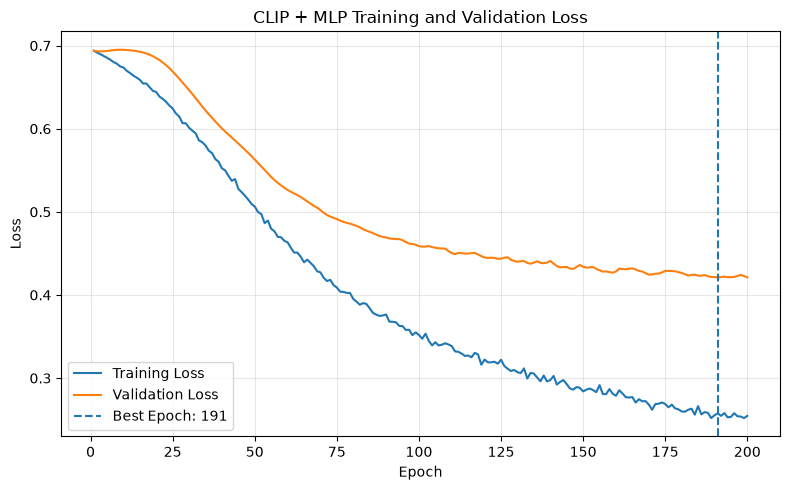

In [35]:

import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.read_csv("results/mlp_training_history.csv")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(history_df["epoch"], history_df["train_loss"],
        label="Training Loss")
ax.plot(history_df["epoch"], history_df["val_loss"],
        label="Validation Loss")

ax.axvline(best_epoch, linestyle="--",
           label=f"Best Epoch: {best_epoch}")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("CLIP + MLP Training and Validation Loss")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("results/mlp_loss_curve.png", dpi=200)
plt.show()


In [37]:

import torch
import torch.nn as nn

checkpoint = torch.load(
    "models/clip_mlp_best.pt",
    map_location="cpu",
    weights_only=True
)

loaded_model = nn.Sequential(
    nn.Linear(1024, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 2)
)

loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

with torch.no_grad():
    predictions = loaded_model(X_val).argmax(dim=1)
    accuracy = (predictions == y_val).float().mean().item()

print(f"Reloaded model validation accuracy: {accuracy:.4f}")
print("Original validation accuracy:", checkpoint["val_accuracy"])

Reloaded model validation accuracy: 0.7980
Original validation accuracy: 0.7979797720909119


In [39]:

import torch
from collections import Counter

# Use the same samples from the previous dataset audit
sample_lookup = {s["id"]: s for s in audit_samples}

def sharp_turn_label(sample):
    turns1 = sample["path 1 descriptors"]["Sharp turns"]
    turns2 = sample["path 2 descriptors"]["Sharp turns"]

    if turns1 < turns2:
        return 0  # Path 1
    elif turns2 < turns1:
        return 1  # Path 2
    else:
        return 2  # Tie

# Use the same IDs as the saved CLIP feature matrices
train_ids = data["train_ids"]
val_ids = data["val_ids"]

y_turn_train = torch.tensor(
    [sharp_turn_label(sample_lookup[i]) for i in train_ids],
    dtype=torch.long
)

y_turn_val = torch.tensor(
    [sharp_turn_label(sample_lookup[i]) for i in val_ids],
    dtype=torch.long
)

print("Training labels:", Counter(y_turn_train.tolist()))
print("Validation labels:", Counter(y_turn_val.tolist()))

print("X_train:", X_train.shape)
print("y_turn_train:", y_turn_train.shape)
print("X_val:", X_val.shape)
print("y_turn_val:", y_turn_val.shape)

assert len(X_train) == len(y_turn_train)
assert len(X_val) == len(y_turn_val)
assert set(y_turn_train.tolist()).issubset({0, 1, 2})
assert set(y_turn_val.tolist()).issubset({0, 1, 2})

print("Sharp turns labels are ready!")


Training labels: Counter({2: 225, 0: 95, 1: 81})
Validation labels: Counter({2: 51, 0: 24, 1: 24})
X_train: torch.Size([401, 1024])
y_turn_train: torch.Size([401])
X_val: torch.Size([99, 1024])
y_turn_val: torch.Size([99])
Sharp turns labels are ready!


In [40]:

import torch.nn as nn

torch.manual_seed(42)

turns_model = nn.Sequential(
    nn.Linear(1024, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 3)
)

print(turns_model)


Sequential(
  (0): Linear(in_features=1024, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=128, out_features=3, bias=True)
)


In [41]:

import torch
import torch.nn as nn
import torch.optim as optim
import copy
import numpy as np

torch.manual_seed(42)

# Calculate class weights using training labels only
counts = torch.bincount(y_turn_train, minlength=3).float()

class_weights = counts.sum() / (3 * counts.clamp(min=1))
class_weights = class_weights / class_weights.mean()

print("Class counts:", counts.tolist())
print("Class weights:", class_weights.tolist())

# Reinitialize the MLP
turns_model = nn.Sequential(
    nn.Linear(1024, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 3)
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(
    turns_model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

best_val_loss = float("inf")
best_state = None
best_epoch_turns = 0

patience = 20
wait = 0
turns_history = []

for epoch in range(200):
    turns_model.train()
    optimizer.zero_grad()

    logits = turns_model(X_train)
    train_loss = criterion(logits, y_turn_train)

    train_loss.backward()
    optimizer.step()

    turns_model.eval()

    with torch.no_grad():
        train_logits = turns_model(X_train)
        val_logits = turns_model(X_val)

        val_loss = criterion(val_logits, y_turn_val).item()

        train_acc = (
            train_logits.argmax(dim=1) == y_turn_train
        ).float().mean().item()

        val_acc = (
            val_logits.argmax(dim=1) == y_turn_val
        ).float().mean().item()

    turns_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss.item(),
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    })

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(turns_model.state_dict())
        best_epoch_turns = epoch + 1
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    if wait >= patience:
        print("Early stopping triggered")
        break

# Restore best model based on validation loss
turns_model.load_state_dict(best_state)
turns_model.eval()

print("\nBest epoch:", best_epoch_turns)
print("Best validation loss:", round(best_val_loss, 4))


Class counts: [95.0, 81.0, 225.0]
Class weights: [1.1560419797897339, 1.355851650238037, 0.4881065785884857]
Epoch  10 | Train Acc: 0.6534 | Val Acc: 0.5657 | Val Loss: 1.0361
Epoch  20 | Train Acc: 0.6484 | Val Acc: 0.5657 | Val Loss: 0.9684
Epoch  30 | Train Acc: 0.6608 | Val Acc: 0.5758 | Val Loss: 0.9183
Epoch  40 | Train Acc: 0.6658 | Val Acc: 0.5758 | Val Loss: 0.8938
Epoch  50 | Train Acc: 0.6808 | Val Acc: 0.5859 | Val Loss: 0.8819
Epoch  60 | Train Acc: 0.6758 | Val Acc: 0.5859 | Val Loss: 0.8735
Epoch  70 | Train Acc: 0.6908 | Val Acc: 0.5859 | Val Loss: 0.8639
Epoch  80 | Train Acc: 0.7007 | Val Acc: 0.5960 | Val Loss: 0.8548
Epoch  90 | Train Acc: 0.7032 | Val Acc: 0.5859 | Val Loss: 0.8469
Epoch 100 | Train Acc: 0.7057 | Val Acc: 0.5859 | Val Loss: 0.8415
Epoch 110 | Train Acc: 0.7132 | Val Acc: 0.5758 | Val Loss: 0.8404
Epoch 120 | Train Acc: 0.7207 | Val Acc: 0.5657 | Val Loss: 0.8413
Epoch 130 | Train Acc: 0.7182 | Val Acc: 0.5758 | Val Loss: 0.8416
Early stopping trigg

In [42]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

turns_model.eval()

with torch.no_grad():
    train_pred = turns_model(X_train).argmax(dim=1)
    val_logits = turns_model(X_val)
    val_pred = val_logits.argmax(dim=1)

train_acc = accuracy_score(
    y_turn_train.numpy(), train_pred.numpy()
)

val_acc = accuracy_score(
    y_turn_val.numpy(), val_pred.numpy()
)

macro_f1 = f1_score(
    y_turn_val.numpy(),
    val_pred.numpy(),
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

majority_label = torch.bincount(
    y_turn_train, minlength=3
).argmax().item()

majority_pred = np.full(len(y_turn_val), majority_label)

majority_acc = accuracy_score(
    y_turn_val.numpy(), majority_pred
)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Majority Baseline: {majority_acc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_turn_val.numpy(),
    val_pred.numpy(),
    labels=[0, 1, 2],
    target_names=["Path 1", "Path 2", "Tie"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_turn_val.numpy(),
    val_pred.numpy(),
    labels=[0, 1, 2]
))


Training Accuracy: 0.7132
Validation Accuracy: 0.5657
Macro F1: 0.5589
Majority Baseline: 0.5152

Classification Report:
              precision    recall  f1-score   support

      Path 1       0.47      0.67      0.55        24
      Path 2       0.39      0.62      0.48        24
         Tie       0.93      0.49      0.64        51

    accuracy                           0.57        99
   macro avg       0.60      0.59      0.56        99
weighted avg       0.69      0.57      0.58        99


Confusion Matrix:
[[16  7  1]
 [ 8 15  1]
 [10 16 25]]


In [43]:

from pathlib import Path
import pandas as pd
import torch

Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

torch.save(
    {
        "model_state_dict": turns_model.state_dict(),
        "input_dim": 1024,
        "hidden_dim": 128,
        "output_dim": 3,
        "best_epoch": best_epoch_turns,
        "best_val_loss": best_val_loss,
        "val_accuracy": val_acc,
        "macro_f1": macro_f1,
        "class_mapping": {
            0: "Path 1",
            1: "Path 2",
            2: "Tie"
        },
        "clip_model": "openai/clip-vit-base-patch32"
    },
    "models/clip_turns_mlp.pt"
)

turns_history_df = pd.DataFrame(turns_history)

turns_history_df.to_csv(
    "results/turns_training_history.csv",
    index=False
)

print("Sharp Turns model saved!")
print("Training history saved!")


Sharp Turns model saved!
Training history saved!


In [44]:

import pandas as pd
import torch

# Previously trained path-length model
loaded_model.eval()
turns_model.eval()

with torch.no_grad():
    length_probs = torch.softmax(
        loaded_model(X_val), dim=1
    )
    turns_probs = torch.softmax(
        turns_model(X_val), dim=1
    )

length_predictions = length_probs.argmax(dim=1).tolist()
turns_predictions = turns_probs.argmax(dim=1).tolist()

length_mapping = {0: "Path 1", 1: "Path 2"}
turns_mapping = {0: "Path 1", 1: "Path 2", 2: "Tie"}

prediction_df = pd.DataFrame({
    "sample_id": val_ids,
    "shorter_path_pred": [
        length_mapping[p] for p in length_predictions
    ],
    "shorter_path_confidence": (
        length_probs.max(dim=1).values.numpy()
    ),
    "fewer_turns_pred": [
        turns_mapping[p] for p in turns_predictions
    ],
    "fewer_turns_confidence": (
        turns_probs.max(dim=1).values.numpy()
    )
})

prediction_df.to_csv(
    "results/attribute_predictions_val.csv",
    index=False
)

display(prediction_df.head(10))

print("Saved:", len(prediction_df), "predictions")


,sample_id,shorter_path_pred,shorter_path_confidence,fewer_turns_pred,fewer_turns_confidence
0,2670,Path 2,0.783889,Path 1,0.473063
1,5041,Path 1,0.569339,Path 2,0.575006
2,3719,Path 2,0.668352,Path 2,0.502058
3,1556,Path 1,0.989578,Path 1,0.732804
4,2580,Path 1,0.986567,Path 1,0.694565
5,6111,Path 1,0.939360,Path 1,0.595152
6,6434,Path 2,0.779585,Path 2,0.666301
7,1482,Path 2,0.713503,Path 2,0.671845
8,3484,Path 2,0.607056,Path 2,0.606589
9,3729,Path 2,0.850837,Path 2,0.564539


Saved: 99 predictions


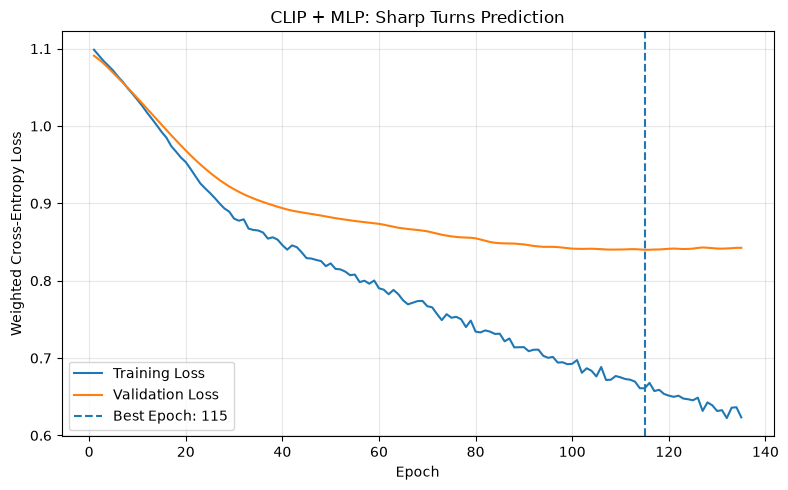

In [45]:

import matplotlib.pyplot as plt

turns_history_df = pd.DataFrame(turns_history)

plt.figure(figsize=(8, 5))
plt.plot(
    turns_history_df["epoch"],
    turns_history_df["train_loss"],
    label="Training Loss"
)
plt.plot(
    turns_history_df["epoch"],
    turns_history_df["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_turns,
    linestyle="--",
    label=f"Best Epoch: {best_epoch_turns}"
)

plt.xlabel("Epoch")
plt.ylabel("Weighted Cross-Entropy Loss")
plt.title("CLIP + MLP: Sharp Turns Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/turns_loss_curve.png",
    dpi=200
)
plt.show()


In [46]:

import torch
import torch.nn as nn

torch.manual_seed(42)

# Linear Head for Sharp Turns prediction
turns_linear = nn.Linear(1024, 3)

print(turns_linear)

# Check input and output dimensions
with torch.no_grad():
    output = turns_linear(X_train[:5])

print("Input shape:", X_train[:5].shape)
print("Output shape:", output.shape)


Linear(in_features=1024, out_features=3, bias=True)
Input shape: torch.Size([5, 1024])
Output shape: torch.Size([5, 3])


In [47]:

import torch
import torch.nn as nn
import torch.optim as optim
import copy

torch.manual_seed(42)

# Create a new linear model
turns_linear = nn.Linear(1024, 3)

# Same class weighting as Sharp Turns MLP
linear_counts = torch.bincount(
    y_turn_train, minlength=3
).float()

linear_weights = linear_counts.sum() / (
    3 * linear_counts.clamp(min=1)
)
linear_weights = linear_weights / linear_weights.mean()

linear_criterion = nn.CrossEntropyLoss(
    weight=linear_weights
)

linear_optimizer = optim.Adam(
    turns_linear.parameters(),
    lr=0.001,
    weight_decay=0.001
)

linear_best_loss = float("inf")
linear_best_state = None
linear_best_epoch = 0

linear_patience = 20
linear_wait = 0
linear_history = []

for epoch in range(200):

    turns_linear.train()
    linear_optimizer.zero_grad()

    train_logits = turns_linear(X_train)
    train_loss = linear_criterion(
        train_logits, y_turn_train
    )

    train_loss.backward()
    linear_optimizer.step()

    turns_linear.eval()

    with torch.no_grad():
        train_logits_eval = turns_linear(X_train)
        val_logits = turns_linear(X_val)

        val_loss = linear_criterion(
            val_logits, y_turn_val
        ).item()

        train_acc = (
            train_logits_eval.argmax(dim=1) == y_turn_train
        ).float().mean().item()

        val_acc = (
            val_logits.argmax(dim=1) == y_turn_val
        ).float().mean().item()

    linear_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss.item(),
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    })

    if val_loss < linear_best_loss - 1e-4:
        linear_best_loss = val_loss
        linear_best_state = copy.deepcopy(
            turns_linear.state_dict()
        )
        linear_best_epoch = epoch + 1
        linear_wait = 0
    else:
        linear_wait += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    if linear_wait >= linear_patience:
        print("Early stopping triggered")
        break

# Restore best checkpoint
turns_linear.load_state_dict(linear_best_state)
turns_linear.eval()

print("\nBest epoch:", linear_best_epoch)
print("Best validation loss:", round(linear_best_loss, 4))


Epoch  10 | Train Acc: 0.6284 | Val Acc: 0.5455 | Val Loss: 1.0722
Epoch  20 | Train Acc: 0.6209 | Val Acc: 0.5556 | Val Loss: 1.0447
Epoch  30 | Train Acc: 0.6284 | Val Acc: 0.5657 | Val Loss: 1.0212
Epoch  40 | Train Acc: 0.6409 | Val Acc: 0.5758 | Val Loss: 1.0005
Epoch  50 | Train Acc: 0.6534 | Val Acc: 0.5657 | Val Loss: 0.9829
Epoch  60 | Train Acc: 0.6584 | Val Acc: 0.5657 | Val Loss: 0.9678
Epoch  70 | Train Acc: 0.6708 | Val Acc: 0.5758 | Val Loss: 0.9549
Epoch  80 | Train Acc: 0.6708 | Val Acc: 0.5758 | Val Loss: 0.9439
Epoch  90 | Train Acc: 0.6783 | Val Acc: 0.5758 | Val Loss: 0.9345
Epoch 100 | Train Acc: 0.6808 | Val Acc: 0.5859 | Val Loss: 0.9263
Epoch 110 | Train Acc: 0.6808 | Val Acc: 0.5859 | Val Loss: 0.9192
Epoch 120 | Train Acc: 0.6883 | Val Acc: 0.5859 | Val Loss: 0.9129
Epoch 130 | Train Acc: 0.6858 | Val Acc: 0.5859 | Val Loss: 0.9074
Epoch 140 | Train Acc: 0.6858 | Val Acc: 0.5859 | Val Loss: 0.9026
Epoch 150 | Train Acc: 0.6833 | Val Acc: 0.5859 | Val Loss: 0.

In [48]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

turns_linear.eval()

with torch.no_grad():
    linear_train_pred = turns_linear(X_train).argmax(dim=1)
    linear_val_pred = turns_linear(X_val).argmax(dim=1)

linear_train_acc = accuracy_score(
    y_turn_train.numpy(),
    linear_train_pred.numpy()
)

linear_val_acc = accuracy_score(
    y_turn_val.numpy(),
    linear_val_pred.numpy()
)

linear_macro_f1 = f1_score(
    y_turn_val.numpy(),
    linear_val_pred.numpy(),
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

print(f"Training Accuracy: {linear_train_acc:.4f}")
print(f"Validation Accuracy: {linear_val_acc:.4f}")
print(f"Macro F1: {linear_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_turn_val.numpy(),
    linear_val_pred.numpy(),
    labels=[0, 1, 2],
    target_names=["Path 1", "Path 2", "Tie"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_turn_val.numpy(),
    linear_val_pred.numpy(),
    labels=[0, 1, 2]
))


Training Accuracy: 0.6883
Validation Accuracy: 0.5859
Macro F1: 0.5798

Classification Report:
              precision    recall  f1-score   support

      Path 1       0.49      0.75      0.59        24
      Path 2       0.42      0.62      0.50        24
         Tie       0.96      0.49      0.65        51

    accuracy                           0.59        99
   macro avg       0.62      0.62      0.58        99
weighted avg       0.71      0.59      0.60        99


Confusion Matrix:
[[18  6  0]
 [ 8 15  1]
 [11 15 25]]


In [49]:

import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

# Re-evaluate the existing Sharp Turns MLP
turns_model.eval()

with torch.no_grad():
    mlp_val_pred = turns_model(X_val).argmax(dim=1)

mlp_val_accuracy = accuracy_score(
    y_turn_val.numpy(),
    mlp_val_pred.numpy()
)

mlp_macro_f1 = f1_score(
    y_turn_val.numpy(),
    mlp_val_pred.numpy(),
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

comparison_df = pd.DataFrame({
    "Model": ["Linear Head", "MLP"],
    "Validation Accuracy": [
        linear_val_acc, mlp_val_accuracy
    ],
    "Macro F1": [
        linear_macro_f1, mlp_macro_f1
    ]
})

display(comparison_df)

Path("results").mkdir(exist_ok=True)

comparison_df.to_csv(
    "results/sharp_turns_model_comparison.csv",
    index=False
)

print("Model comparison saved!")


,Model,Validation Accuracy,Macro F1
0,Linear Head,0.585859,0.579838
1,MLP,0.565657,0.558874


Model comparison saved!


In [50]:

import torch
import pandas as pd
from pathlib import Path

Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

torch.save(
    {
        "model_state_dict": turns_linear.state_dict(),
        "input_dim": 1024,
        "output_dim": 3,
        "best_epoch": linear_best_epoch,
        "best_val_loss": linear_best_loss,
        "val_accuracy": linear_val_acc,
        "macro_f1": linear_macro_f1,
        "clip_model": "openai/clip-vit-base-patch32"
    },
    "models/clip_turns_linear.pt"
)

linear_history_df = pd.DataFrame(linear_history)

linear_history_df.to_csv(
    "results/turns_linear_history.csv",
    index=False
)

print("Linear checkpoint saved!")
print("Linear training history saved!")


Linear checkpoint saved!
Linear training history saved!


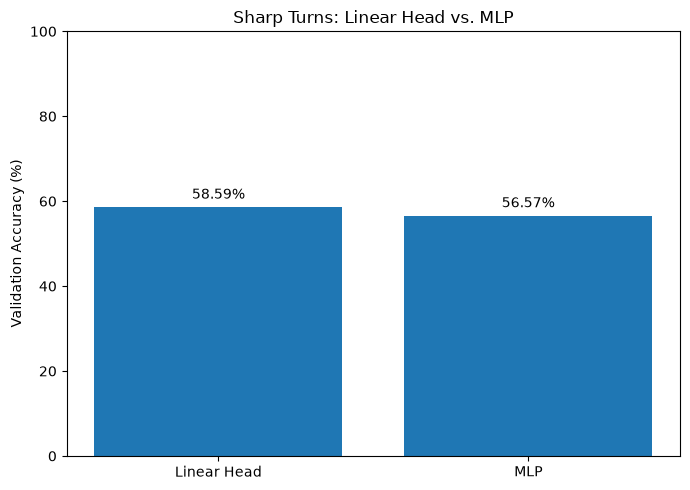

In [51]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

models = ["Linear Head", "MLP"]
accuracies = [
    linear_val_acc * 100,
    mlp_val_accuracy * 100
]

bars = ax.bar(models, accuracies)

ax.set_ylabel("Validation Accuracy (%)")
ax.set_title("Sharp Turns: Linear Head vs. MLP")
ax.set_ylim(0, 100)

for bar, acc in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{acc:.2f}%",
        ha="center"
    )

fig.tight_layout()
fig.savefig(
    "results/sharp_turns_comparison.png",
    dpi=200
)
plt.show()


In [52]:

import torch
import torch.nn as nn

checkpoint = torch.load(
    "models/clip_turns_linear.pt",
    map_location="cpu",
    weights_only=True
)

reloaded_linear = nn.Linear(1024, 3)

reloaded_linear.load_state_dict(
    checkpoint["model_state_dict"]
)

reloaded_linear.eval()

with torch.no_grad():
    predictions = reloaded_linear(X_val).argmax(dim=1)
    accuracy = (predictions == y_turn_val).float().mean().item()

print(f"Reloaded Linear Accuracy: {accuracy:.4f}")
print(f"Saved Linear Accuracy: {checkpoint['val_accuracy']:.4f}")

assert abs(accuracy - checkpoint["val_accuracy"]) < 1e-6
print("Checkpoint verification passed!")


Reloaded Linear Accuracy: 0.5859
Saved Linear Accuracy: 0.5859
Checkpoint verification passed!
